# Lab Problem 1 : Linear Regression with BGD & SGD

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set a random seed for reproducibility
np.random.seed(42)

Task 1 — Data Preparation & Feature Scaling

In [ ]:
# 1. Load the dataset
housing = fetch_california_housing()
X, y = housing.data, housing.target

# 2. Split into 80% training and 20% testing sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Standardize the features (fit on train, transform both train and test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# 4. Add a bias column of 1s to X_train and X_test
X_train = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
X_test = np.c_[np.ones((X_test_scaled.shape[0], 1)), X_test_scaled]

print(f"Training features shape (with bias): {X_train.shape}")
print(f"Testing features shape (with bias):  {X_test.shape}")

Training features shape (with bias): (16512, 9)
Testing features shape (with bias):  (4128, 9)


Task 2 (Part A) — Cost Function & Batch Gradient Descent Implementation

In [ ]:
def compute_mse(X, y, theta):
  """Computes the Mean Squared Error (with 1/2 factor for clean derivatives)."""
  m = len(y)
  predictions = X.dot(theta)
  errors = predictions - y
  cost = (1 / (2 * m)) * np.sum(errors**2)
  return cost


def batch_gradient_descent(X, y, alpha=0.01, iterations=500):
  """Performs Batch Gradient Descent using the entire dataset per step."""
  m, n = X.shape
  theta = np.zeros(n)  # Initialize weights to zeros
  cost_history = []

  for _ in range(iterations):
    predictions = X.dot(theta)
    errors = predictions - y

    # Compute gradient across ALL 'm' samples simultaneously
    gradients = (1 / m) * X.T.dot(errors)

    # Update weights
    theta = theta - alpha * gradients

    # Record cost at this iteration
    cost_history.append(compute_mse(X, y, theta))

  return theta, cost_history

Task 2 (Part B) — Cost Function Visualization

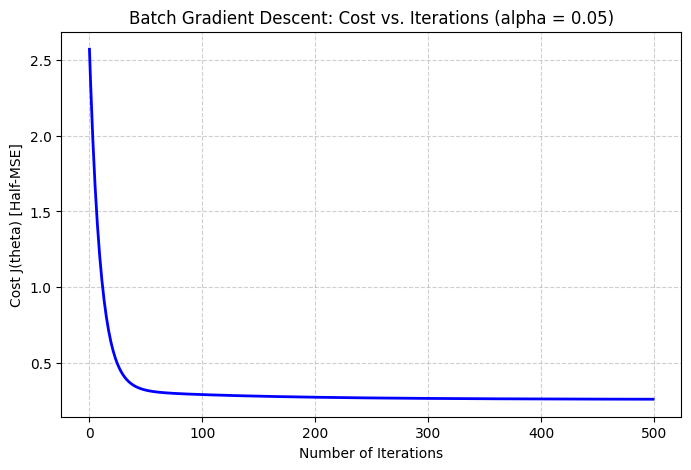

Initial Cost: 2.5705
Final Cost:   0.2606


In [ ]:
# Run BGD with a standard learning rate
theta_bgd, cost_history_bgd = batch_gradient_descent(
    X_train, y_train, alpha=0.05, iterations=500
)

# Plot Cost vs. Number of Iterations
plt.figure(figsize=(8, 5))
plt.plot(range(len(cost_history_bgd)), cost_history_bgd, color='blue', linewidth=2)
plt.title('Batch Gradient Descent: Cost vs. Iterations (alpha = 0.05)')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost J(theta) [Half-MSE]')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f'Initial Cost: {cost_history_bgd[0]:.4f}')
print(f'Final Cost:   {cost_history_bgd[-1]:.4f}')

Task 3 — Learning Rate ($\alpha$) Optimization

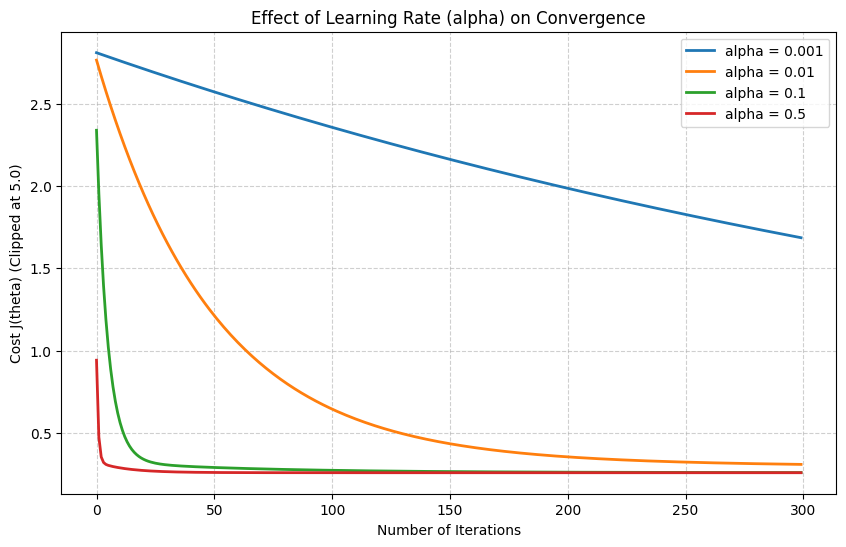

In [ ]:
alphas = [0.001, 0.01, 0.1, 0.5]
iterations = 300

plt.figure(figsize=(10, 6))

for alpha in alphas:
  _, cost_hist = batch_gradient_descent(
      X_train, y_train, alpha=alpha, iterations=iterations
  )
  # Clip extreme values if divergence occurs so the plot remains readable
  cost_hist_clipped = np.clip(cost_hist, 0, 5)
  plt.plot(
      range(iterations), cost_hist_clipped, label=f'alpha = {alpha}', linewidth=2
  )

plt.title('Effect of Learning Rate (alpha) on Convergence')
plt.xlabel('Number of Iterations')
plt.ylabel('Cost J(theta) (Clipped at 5.0)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Task 4 — Stochastic Gradient Descent (SGD) vs. Batch Gradient Descent (BGD)

BGD Execution Time (300 iterations): 0.2512 seconds | Final Cost: 0.2598
SGD Execution Time (15 epochs):      3.7080 seconds | Final Cost: 0.2621


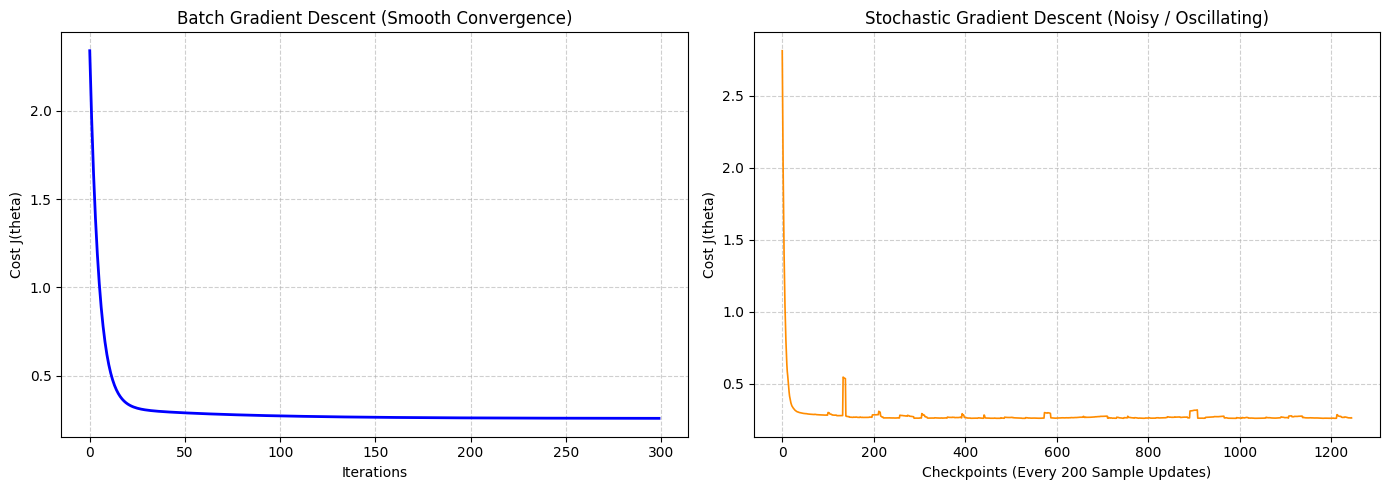

In [ ]:
def stochastic_gradient_descent(X, y, alpha=0.001, epochs=30):
  """Performs Stochastic Gradient Descent (1 sample per weight update)."""
  m, n = X.shape
  theta = np.zeros(n)
  cost_history = []

  for epoch in range(epochs):
    # Shuffle the data at the start of every epoch to prevent cycles
    indices = np.random.permutation(m)
    X_shuffled = X[indices]
    y_shuffled = y[indices]

    for i in range(m):
      # Extract a single training sample (keep 2D shape for matrix math)
      xi = X_shuffled[i : i + 1]
      yi = y_shuffled[i : i + 1]

      prediction = xi.dot(theta)
      error = prediction - yi

      # Gradient for just this 1 sample
      gradient = xi.T.dot(error)
      theta = theta - alpha * gradient

      # Record cost every 200 steps to visualize the noisy trajectory clearly
      if i % 200 == 0:
        cost_history.append(compute_mse(X, y, theta))

  return theta, cost_history


# --- Compare Execution Time & Smoothness ---

# 1. Run Batch Gradient Descent
start_bgd = time.time()
theta_bgd, cost_bgd = batch_gradient_descent(X_train, y_train, alpha=0.1, iterations=300)
time_bgd = time.time() - start_bgd

# 2. Run Stochastic Gradient Descent
# Note: SGD requires a smaller learning rate so single noisy samples don't blow up weights
start_sgd = time.time()
theta_sgd, cost_sgd = stochastic_gradient_descent(X_train, y_train, alpha=0.0005, epochs=15)
time_sgd = time.time() - start_sgd

print(f"BGD Execution Time (300 iterations): {time_bgd:.4f} seconds | Final Cost: {cost_bgd[-1]:.4f}")
print(f"SGD Execution Time (15 epochs):      {time_sgd:.4f} seconds | Final Cost: {cost_sgd[-1]:.4f}")

# Side-by-side comparison plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(cost_bgd, color='blue', linewidth=2)
axes[0].set_title('Batch Gradient Descent (Smooth Convergence)')
axes[0].set_xlabel('Iterations')
axes[0].set_ylabel('Cost J(theta)')
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(cost_sgd, color='darkorange', linewidth=1.2)
axes[1].set_title('Stochastic Gradient Descent (Noisy / Oscillating)')
axes[1].set_xlabel('Checkpoints (Every 200 Sample Updates)')
axes[1].set_ylabel('Cost J(theta)')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Task 5 — Final Evaluation on the Test Set

In [ ]:
# Train our best-performing model (BGD with alpha=0.1, 1000 iterations for full convergence)
best_theta, _ = batch_gradient_descent(X_train, y_train, alpha=0.1, iterations=1000)

# Predict on the unseen test set
y_test_pred = X_test.dot(best_theta)

# Calculate standard Mean Squared Error (MSE) and Root Mean Squared Error (RMSE)
test_mse = np.mean((y_test_pred - y_test) ** 2)
test_rmse = np.sqrt(test_mse)

print("--- Final Evaluation on Test Set ---")
print(f"Test Mean Squared Error (MSE):       {test_mse:.4f}")
print(f"Test Root Mean Squared Error (RMSE): {test_rmse:.4f}")
print("\nLearned Model Weights (Theta):")
feature_names = ["Bias (Intercept)"] + list(housing.feature_names)
for name, weight in zip(feature_names, best_theta):
  print(f"  {name:<18}: {weight:.4f}")

--- Final Evaluation on Test Set ---
Test Mean Squared Error (MSE):       0.5560
Test Root Mean Squared Error (RMSE): 0.7457

Learned Model Weights (Theta):
  Bias (Intercept)  : 2.0719
  MedInc            : 0.8554
  HouseAge          : 0.1228
  AveRooms          : -0.2962
  AveBedrms         : 0.3407
  Population        : -0.0022
  AveOccup          : -0.0409
  Latitude          : -0.8942
  Longitude         : -0.8672
